# Anexo. Imágenes como datos: el caso *Digit Recognizer* (MNIST en CSV)

**Módulo ETCDFM (5104) · UD2: Formatos de fichero de datos**

---

En los bloques anteriores hemos trabajado con datos tabulares, documentos XML y JSON. Pero buena parte del *machine learning* actual trabaja con **imágenes**. ¿Cómo se guarda una imagen para que un modelo pueda aprender de ella?

En este anexo lo veremos con un ejemplo real: la competición de Kaggle [**Digit Recognizer**](https://www.kaggle.com/competitions/digit-recognizer/), que distribuye el famoso conjunto **MNIST** (dígitos escritos a mano) **en formato CSV**. Al terminar habremos generado el fichero `submission.csv` listo para subir a la competición.

## Contenidos

A.1. ¿Qué es una imagen digital para un ordenador?
A.2. Cómo se guarda una imagen en un CSV: el aplanado (*flattening*)
A.3. Carga de los datos con pandas
A.4. Exploración y calidad de los datos
A.5. Reconstrucción y visualización de las imágenes
A.6. Otras formas de almacenar imágenes: NPY, NPZ y PNG
A.7. Preparación de los datos para el modelo
A.8. Entrenamiento y validación de un clasificador
A.9. Generación del fichero `submission.csv`
A.10. Subida a Kaggle y resumen

### Ficheros de la competición

En la misma carpeta que este cuaderno deben estar los tres ficheros descargados de Kaggle:

| Fichero | Contenido |
|---|---|
| `train.csv` | 42 000 imágenes **etiquetadas**: columna `label` + 784 columnas de píxeles |
| `test.csv` | 28 000 imágenes **sin etiqueta**: solo las 784 columnas de píxeles |
| `sample_submission.csv` | Ejemplo del formato de entrega: `ImageId,Label` |

Librerías necesarias: `numpy`, `pandas`, `matplotlib`, `scikit-learn` y `pillow` (esta última se instala junto con matplotlib).

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Carpeta de datos = carpeta del cuaderno; las salidas auxiliares van a 'salida/'
DATOS = Path('.')
SALIDA = Path('salida')
SALIDA.mkdir(exist_ok=True)

SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams['figure.dpi'] = 100

for f in ['train.csv', 'test.csv', 'sample_submission.csv']:
    p = DATOS / f
    print(f'{f:<24} {p.stat().st_size / 1e6:8.1f} MB')

train.csv                    76.8 MB
test.csv                     51.1 MB
sample_submission.csv         0.2 MB


## A.1 ¿Qué es una imagen digital para un ordenador?

Para un ordenador, una imagen es simplemente una **matriz de números**. Cada número es un **píxel** e indica su intensidad.

- **Imagen en escala de grises**: matriz de `alto × ancho`. Cada píxel es un entero entre **0 (negro)** y **255 (blanco)**, es decir, cabe en un byte (`uint8`).
- **Imagen en color (RGB)**: tensor de `alto × ancho × 3`. Tres matrices superpuestas (rojo, verde, azul).
- **Lote de imágenes** (lo que consume un modelo): tensor de `n_imágenes × alto × ancho (× canales)`.

> En MNIST el convenio está "invertido": el **fondo vale 0** (negro) y el **trazo vale hasta 255**. Por eso los dígitos se ven blancos sobre negro.

Construyamos a mano una imagen diminuta de 7×7 píxeles para comprobarlo:

Matriz de píxeles (dtype = uint8 , shape = (7, 7) )
[[  0   0   0   0   0   0   0]
 [  0 255 255 255 255 255   0]
 [  0   0   0 200   0   0   0]
 [  0   0   0 200   0   0   0]
 [  0   0   0 200   0   0   0]
 [  0   0   0 200   0   0   0]
 [  0   0   0   0   0   0   0]]


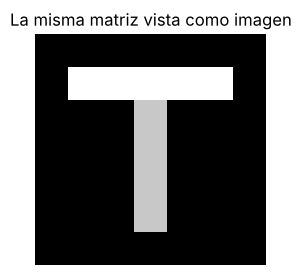

In [2]:
# Una "letra T" de 7x7 píxeles en escala de grises
mini = np.zeros((7, 7), dtype=np.uint8)
mini[1, 1:6] = 255      # barra horizontal
mini[2:6, 3] = 200      # barra vertical, algo más gris

print('Matriz de píxeles (dtype =', mini.dtype, ', shape =', mini.shape, ')')
print(mini)

fig, ax = plt.subplots(figsize=(3, 3))
ax.imshow(mini, cmap='gray', vmin=0, vmax=255)
ax.set_title('La misma matriz vista como imagen')
ax.axis('off')
plt.show()

shape = (2, 3, 3) -> 18 números, 18 bytes


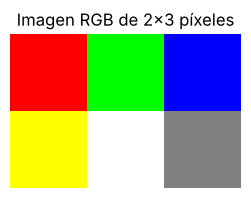

In [3]:
# Una imagen en color es un tensor alto x ancho x 3 (R, G, B)
rgb = np.zeros((2, 3, 3), dtype=np.uint8)
rgb[0, 0] = [255, 0, 0]       # rojo
rgb[0, 1] = [0, 255, 0]       # verde
rgb[0, 2] = [0, 0, 255]       # azul
rgb[1, 0] = [255, 255, 0]     # amarillo
rgb[1, 1] = [255, 255, 255]   # blanco
rgb[1, 2] = [128, 128, 128]   # gris

print('shape =', rgb.shape, '->', rgb.size, 'números,', rgb.nbytes, 'bytes')
fig, ax = plt.subplots(figsize=(3, 2))
ax.imshow(rgb)
ax.set_title('Imagen RGB de 2x3 píxeles')
ax.axis('off')
plt.show()

## A.2 Cómo se guarda una imagen en un CSV: el aplanado (*flattening*)

Un CSV es una **tabla**: cada fila es un registro y cada columna un atributo. Una imagen de 28×28 es una matriz, no una fila. Para meterla en una tabla se **aplana**: se leen los píxeles **fila a fila** (de izquierda a derecha y de arriba abajo) y se colocan uno detrás de otro.

```
Imagen 28 x 28                         Fila del CSV (784 valores)
┌──────────────────────┐
│ p0   p1   ...   p27  │  fila 0   ──►  pixel0 ... pixel27
│ p28  p29  ...   p55  │  fila 1   ──►  pixel28 ... pixel55
│ ...                  │
│ p756 ...        p783 │  fila 27  ──►  pixel756 ... pixel783
└──────────────────────┘
```

Este orden se llama **row-major** (orden por filas, el de C y NumPy). La relación entre la posición en la imagen y el nombre de la columna es:

$$\text{pixel}_k \quad\text{con}\quad k = i \cdot 28 + j \qquad\Longleftrightarrow\qquad i = k \,//\, 28,\;\; j = k \,\%\, 28$$

donde $i$ es la fila (0–27) y $j$ la columna (0–27). Así, `pixel0` es la esquina superior izquierda y `pixel783` la inferior derecha.

En NumPy, aplanar y desaplanar es una sola operación: `reshape`.

In [4]:
# Aplanar la mini-imagen 7x7 -> vector de 49 valores, y volver atrás
plano = mini.reshape(-1)          # equivalente a mini.flatten()
print('Aplanada:', plano.shape)
print(plano)

recuperada = plano.reshape(7, 7)
print('\n¿Recuperamos exactamente la misma imagen?', np.array_equal(mini, recuperada))

# Comprobación de la fórmula k = i*ancho + j
i, j = 2, 3
k = i * 7 + j
print(f'Píxel (fila={i}, col={j}) -> posición k={k} -> valor {plano[k]} (en la matriz: {mini[i, j]})')

Aplanada: (49,)
[  0   0   0   0   0   0   0   0 255 255 255 255 255   0   0   0   0 200
   0   0   0   0   0   0 200   0   0   0   0   0   0 200   0   0   0   0
   0   0 200   0   0   0   0   0   0   0   0   0   0]

¿Recuperamos exactamente la misma imagen? True
Píxel (fila=2, col=3) -> posición k=17 -> valor 200 (en la matriz: 200)


**Ventajas e inconvenientes de guardar imágenes en CSV**

| ✔ Ventajas | ✘ Inconvenientes |
|---|---|
| Se abre con cualquier herramienta (pandas, Excel, R…) | Se pierde la estructura 2D: hay que conocer el alto y el ancho para reconstruir |
| Encaja directamente con modelos tabulares (cada píxel = una *feature*) | Texto plano: cada píxel ocupa 1–4 caracteres en lugar de 1 byte |
| Imágenes y etiquetas en el mismo fichero | Inviable para imágenes grandes o en color (una foto 224×224×3 = 150 528 columnas) |

Por eso el CSV solo se usa con imágenes **pequeñas y en escala de grises** (MNIST, Fashion-MNIST…). Lo veremos con números en el apartado A.6.

## A.3 Carga de los datos con pandas

Leemos los dos ficheros con `read_csv`. Como todos los valores son enteros entre 0 y 255, podemos indicar `dtype='uint8'` para que cada píxel ocupe **1 byte** en memoria en lugar de los 8 bytes del `int64` que pandas usa por defecto.

In [5]:
t0 = time.time()
train = pd.read_csv(DATOS / 'train.csv', dtype='uint8')
test = pd.read_csv(DATOS / 'test.csv', dtype='uint8')
print(f'Lectura completada en {time.time() - t0:.1f} s\n')

print('train:', train.shape, '-> 1 columna label + 784 píxeles')
print('test: ', test.shape, '-> 784 píxeles (sin label)')

Lectura completada en 3.4 s

train: (42000, 785) -> 1 columna label + 784 píxeles
test:  (28000, 784) -> 784 píxeles (sin label)


In [6]:
# Las primeras filas: la etiqueta y una ristra de píxeles (casi todos 0 en los bordes)
train.iloc[:5, :12]

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10
0,1,0,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0


In [7]:
# ¿Cuánto ocupa en memoria según el tipo de dato?
mem_uint8 = train.memory_usage(deep=True).sum() / 1e6
mem_int64 = train.astype('int64').memory_usage(deep=True).sum() / 1e6
print(f'Con dtype int64 (por defecto): {mem_int64:7.1f} MB')
print(f'Con dtype uint8:               {mem_uint8:7.1f} MB  (x{mem_int64 / mem_uint8:.0f} menos)')

Con dtype int64 (por defecto):   263.8 MB
Con dtype uint8:                  33.0 MB  (x8 menos)


## A.4 Exploración y calidad de los datos

Antes de entrenar comprobamos, como con cualquier dataset:

1. Que no haya **valores nulos**.
2. Que los píxeles estén en el **rango esperado** [0, 255].
3. Cómo se **distribuyen las clases** (¿está equilibrado?).
4. Si hay **imágenes duplicadas**.

In [8]:
y = train['label']
X = train.drop(columns='label')

print('Valores nulos en train:', train.isna().sum().sum())
print('Valores nulos en test: ', test.isna().sum().sum())
print(f'Rango de píxeles train: [{X.values.min()}, {X.values.max()}]')
print(f'Rango de píxeles test:  [{test.values.min()}, {test.values.max()}]')
print('Imágenes duplicadas en train:', X.duplicated().sum())

Valores nulos en train: 0
Valores nulos en test:  0
Rango de píxeles train: [0, 255]
Rango de píxeles test:  [0, 255]


Imágenes duplicadas en train: 0


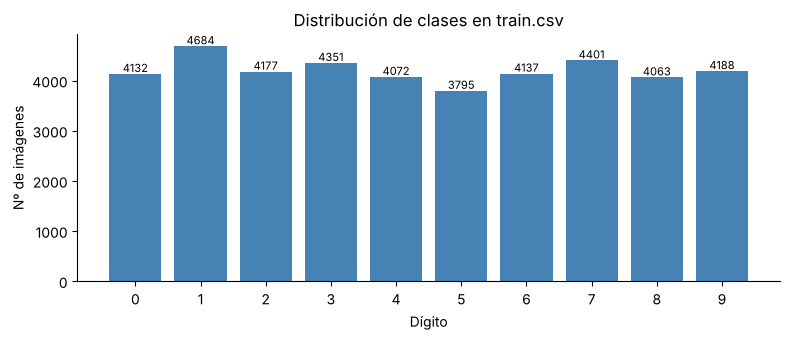

Clase menos frecuente: 5 (3795) · más frecuente: 1 (4684)


In [9]:
conteo = y.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(conteo.index, conteo.values, color='steelblue')
ax.set_xticks(range(10))
ax.set_xlabel('Dígito')
ax.set_ylabel('Nº de imágenes')
ax.set_title('Distribución de clases en train.csv')
for d, n in conteo.items():
    ax.text(d, n + 40, n, ha='center', fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

print(f'Clase menos frecuente: {conteo.idxmin()} ({conteo.min()}) · más frecuente: {conteo.idxmax()} ({conteo.max()})')

El conjunto está **razonablemente equilibrado** (entre ~3 800 y ~4 700 ejemplos por clase), así que la *accuracy* (porcentaje de aciertos) será una métrica adecuada. Es, de hecho, la métrica que usa Kaggle en esta competición.

¿Qué píxeles contienen información? Si un píxel vale 0 en **todas** las imágenes, no aporta nada al modelo:

Píxeles que valen 0 en todas las imágenes: 76 de 784


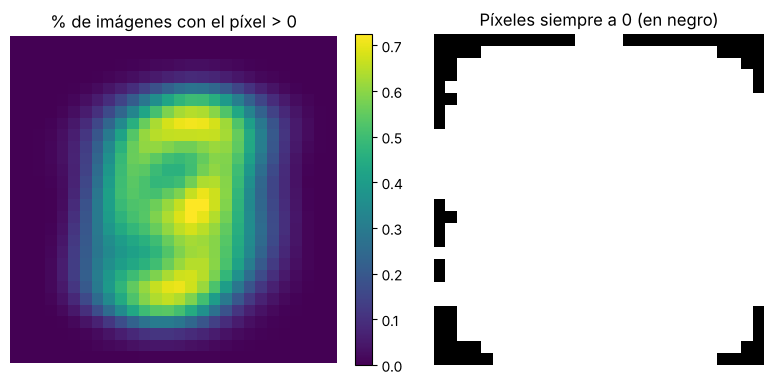

In [10]:
siempre_cero = (X.max(axis=0) == 0)
print(f'Píxeles que valen 0 en todas las imágenes: {siempre_cero.sum()} de 784')

# Proporción de imágenes en las que cada píxel está "encendido", vista como imagen 28x28
encendido = (X > 0).mean(axis=0).values.reshape(28, 28)

fig, axes = plt.subplots(1, 2, figsize=(8, 3.8))
im = axes[0].imshow(encendido, cmap='viridis')
axes[0].set_title('% de imágenes con el píxel > 0')
fig.colorbar(im, ax=axes[0], fraction=0.046)
axes[1].imshow(siempre_cero.values.reshape(28, 28), cmap='gray_r')
axes[1].set_title('Píxeles siempre a 0 (en negro)')
for a in axes:
    a.axis('off')
plt.tight_layout()
plt.show()

Los bordes de la imagen están prácticamente vacíos: los dígitos de MNIST se centraron en una caja de 20×20 dentro del lienzo de 28×28. Esta información será útil para reducir la dimensionalidad (apartado A.8).

## A.5 Reconstrucción y visualización de las imágenes

Para "ver" un registro del CSV basta con **desaplanarlo**: tomar sus 784 valores y aplicar `reshape(28, 28)`.

Primero veamos una imagen **con sus valores numéricos**, para comprobar que lo que pinta `imshow` es exactamente la matriz del CSV:

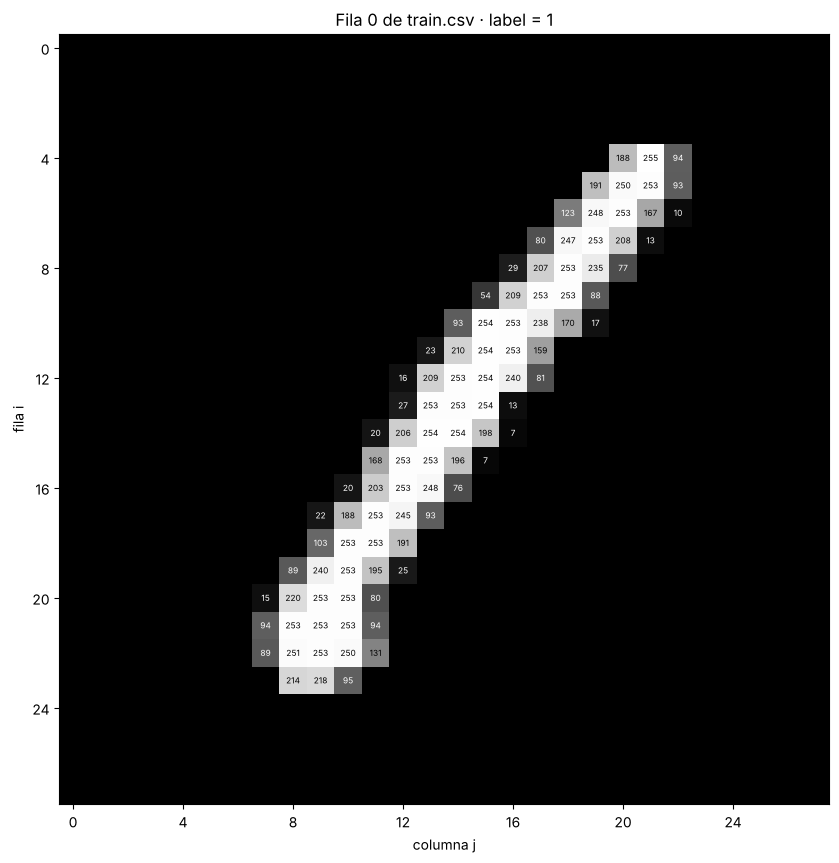

In [11]:
idx = 0
fila = X.iloc[idx].values           # 784 valores de la fila 0
img = fila.reshape(28, 28)           # desaplanado -> matriz 28x28

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img, cmap='gray', vmin=0, vmax=255)
for i in range(28):
    for j in range(28):
        v = img[i, j]
        if v > 0:
            ax.text(j, i, v, ha='center', va='center', fontsize=6,
                    color='black' if v > 128 else 'white')
ax.set_xticks(range(0, 28, 4))
ax.set_yticks(range(0, 28, 4))
ax.set_xlabel('columna j')
ax.set_ylabel('fila i')
ax.set_title(f'Fila {idx} de train.csv · label = {y.iloc[idx]}')
plt.show()

In [12]:
# Comprobamos la fórmula k = i*28 + j con un píxel concreto del trazo
i, j = np.argwhere(img == img.max())[0]
k = i * 28 + j
print(f'Píxel (i={i}, j={j}) -> columna "pixel{k}" del CSV')
print(f'  valor en la matriz : {img[i, j]}')
print(f'  valor en el CSV    : {X.iloc[idx][f"pixel{k}"]}')

Píxel (i=4, j=21) -> columna "pixel133" del CSV
  valor en la matriz : 255
  valor en el CSV    : 255


### Una muestra aleatoria del conjunto de entrenamiento

Escribimos una pequeña función reutilizable para pintar una rejilla de imágenes con su etiqueta:

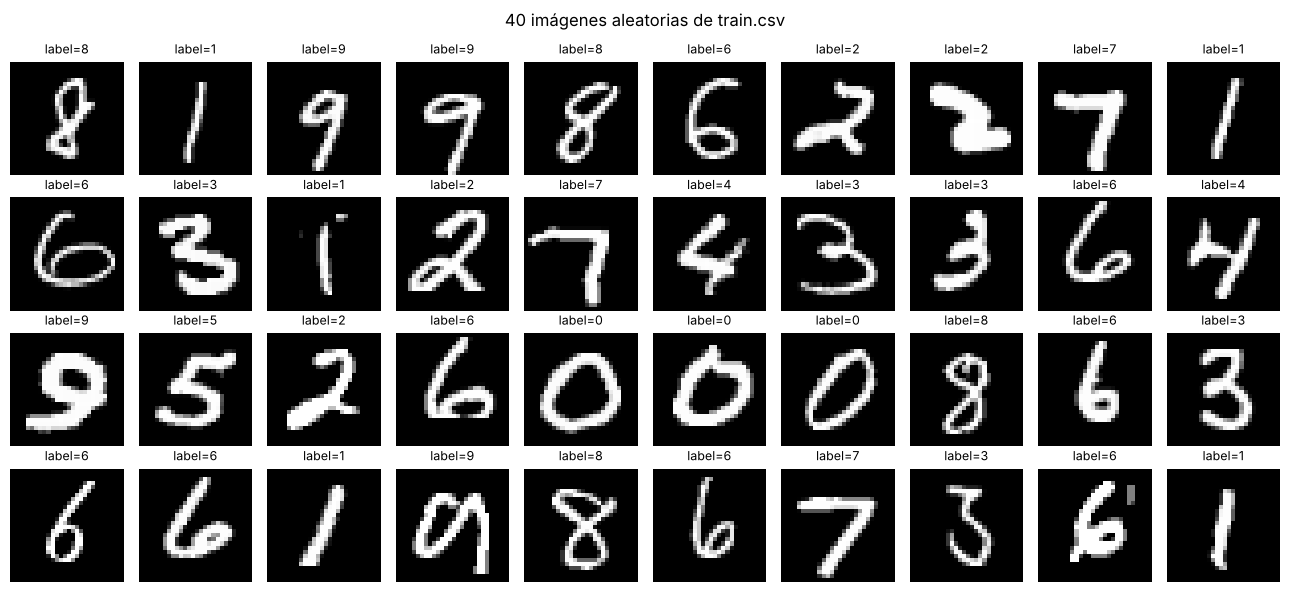

In [13]:
def mostrar_rejilla(imagenes, titulos, filas, columnas, titulo_general='', cmap='gray', figsize=None):
    # imagenes: array (n, 784) o (n, 28, 28); titulos: lista de textos
    imagenes = np.asarray(imagenes).reshape(-1, 28, 28)
    figsize = figsize or (columnas * 1.3, filas * 1.5)
    fig, axes = plt.subplots(filas, columnas, figsize=figsize)
    for ax, im, t in zip(axes.ravel(), imagenes, titulos):
        ax.imshow(im, cmap=cmap)
        ax.set_title(t, fontsize=9)
    for ax in axes.ravel():
        ax.axis('off')
    if titulo_general:
        fig.suptitle(titulo_general)
    plt.tight_layout()
    plt.show()


muestra = np.random.choice(len(X), 40, replace=False)
mostrar_rejilla(X.values[muestra], [f'label={l}' for l in y.values[muestra]],
                4, 10, '40 imágenes aleatorias de train.csv')

### Variabilidad dentro de cada clase

Cada dígito se escribe de muchas formas distintas: inclinado, más grueso, con o sin "barrita" en el 7… Esa variabilidad es la que tiene que aprender el modelo.

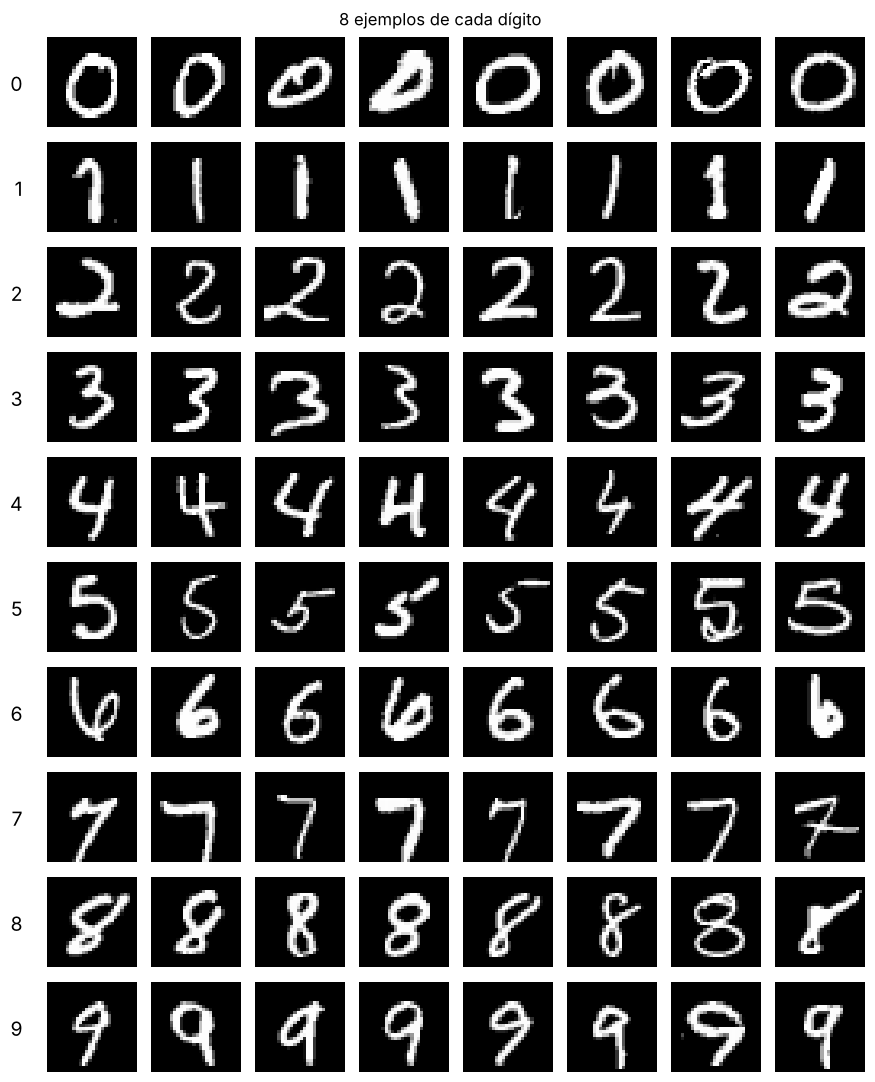

In [14]:
n_por_clase = 8
fig, axes = plt.subplots(10, n_por_clase, figsize=(n_por_clase * 1.1, 11))
for d in range(10):
    idxs = np.random.choice(np.where(y.values == d)[0], n_por_clase, replace=False)
    for c, k in enumerate(idxs):
        axes[d, c].imshow(X.values[k].reshape(28, 28), cmap='gray')
        axes[d, c].axis('off')
    axes[d, 0].text(-8, 14, str(d), fontsize=14, va='center', ha='right')
fig.suptitle('8 ejemplos de cada dígito')
plt.tight_layout()
plt.show()

### La "imagen media" de cada dígito

Como cada imagen es un vector de números, podemos hacer **operaciones aritméticas** con ellas. Por ejemplo, promediar todas las imágenes de una misma clase:

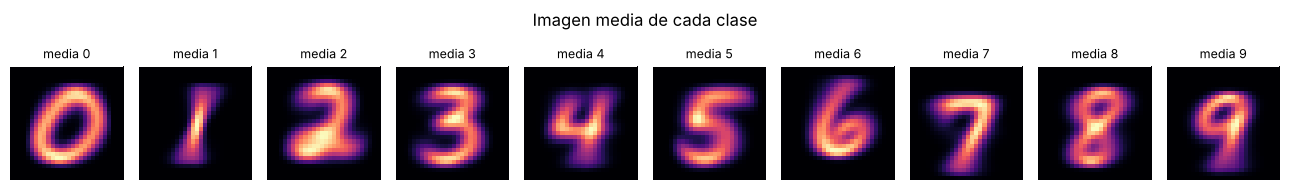

In [15]:
medias = np.stack([X.values[y.values == d].mean(axis=0) for d in range(10)])
mostrar_rejilla(medias, [f'media {d}' for d in range(10)], 1, 10,
                'Imagen media de cada clase', cmap='magma', figsize=(13, 2))

### Imágenes del conjunto de test

El fichero `test.csv` tiene el mismo formato, **pero sin la columna `label`**: es justo lo que tendremos que predecir.

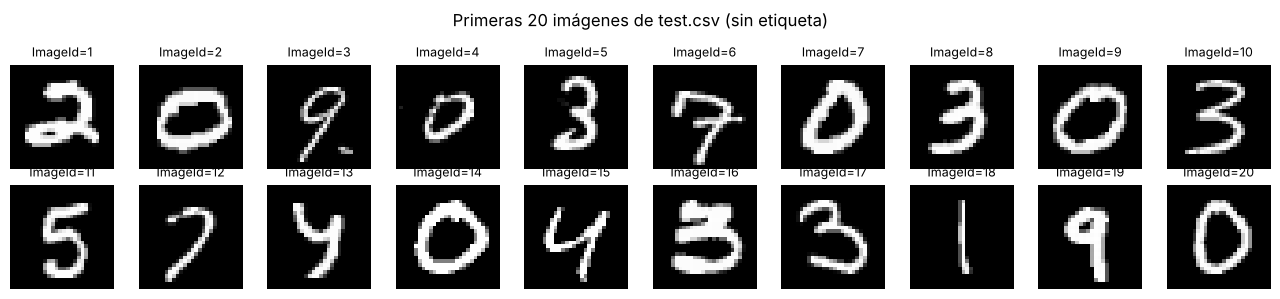

In [16]:
muestra_t = np.arange(20)
mostrar_rejilla(test.values[muestra_t], [f'ImageId={k + 1}' for k in muestra_t],
                2, 10, 'Primeras 20 imágenes de test.csv (sin etiqueta)')

## A.6 Otras formas de almacenar imágenes: NPY, NPZ y PNG

El CSV no es la única opción (ni la más eficiente). Comparemos cómo ocuparía el **mismo conjunto de entrenamiento** en otros formatos habituales en ML:

| Formato | Descripción | Uso típico |
|---|---|---|
| **CSV** | Texto plano, una imagen por fila | Datasets pequeños, competiciones introductorias |
| **NPY** | Volcado binario de un array NumPy (1 byte por píxel en `uint8`) | Caché rápida de datos ya procesados |
| **NPZ** | Varios arrays NumPy en un ZIP, opcionalmente comprimido | Distribuir `X` e `y` juntos (así se distribuye MNIST en `keras.datasets`) |
| **PNG / JPG** | Un fichero por imagen, organizados en carpetas por clase | Datasets de visión "reales" (ImageNet, `ImageFolder` de PyTorch) |
| **IDX** | Formato binario original de MNIST (cabecera + bytes) | Histórico |
| **TFRecord / HDF5 / Parquet** | Contenedores binarios para millones de muestras | Producción y entrenamiento a gran escala (ver Bloque 3) |

In [17]:
# Pasamos a arrays NumPy con la forma natural de un lote de imágenes: (n, 28, 28)
X_img = X.values.reshape(-1, 28, 28)
y_arr = y.values
print('X_img:', X_img.shape, X_img.dtype, '| y:', y_arr.shape, y_arr.dtype)

np.save(SALIDA / 'train_X.npy', X_img)
np.save(SALIDA / 'train_y.npy', y_arr)
np.savez_compressed(SALIDA / 'train.npz', X=X_img, y=y_arr)

tam = {
    'CSV (train.csv)': (DATOS / 'train.csv').stat().st_size,
    'NPY (X + y)': (SALIDA / 'train_X.npy').stat().st_size + (SALIDA / 'train_y.npy').stat().st_size,
    'NPZ comprimido': (SALIDA / 'train.npz').stat().st_size,
}
for k, v in tam.items():
    print(f'{k:<18} {v / 1e6:7.1f} MB')

X_img: (42000, 28, 28) uint8 | y: (42000,) uint8


CSV (train.csv)       76.8 MB
NPY (X + y)           33.0 MB
NPZ comprimido         6.9 MB


NPZ leído en 0.12 s -> (42000, 28, 28) uint8


¿Idéntico al CSV? True


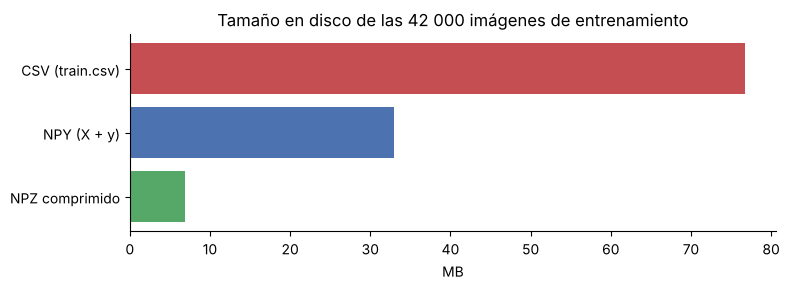

In [18]:
# Lectura: el NPZ conserva forma y tipo, no hay que adivinar nada
t0 = time.time()
datos_npz = np.load(SALIDA / 'train.npz')
X_npz, y_npz = datos_npz['X'], datos_npz['y']
print(f'NPZ leído en {time.time() - t0:.2f} s ->', X_npz.shape, X_npz.dtype)
print('¿Idéntico al CSV?', np.array_equal(X_npz, X_img) and np.array_equal(y_npz, y_arr))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(list(tam.keys()), [v / 1e6 for v in tam.values()], color=['#c44e52', '#4c72b0', '#55a868'])
ax.set_xlabel('MB')
ax.set_title('Tamaño en disco de las 42 000 imágenes de entrenamiento')
ax.invert_yaxis()
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Una imagen por fichero: PNG en carpetas por clase

En los datasets de visión "de verdad" lo habitual es guardar **cada imagen como un fichero** (PNG, JPG) y usar la **estructura de carpetas** como etiqueta:

```
png_muestra/
├── 0/  img_00001.png  img_00057.png ...
├── 1/  ...
└── 9/  ...
```

Exportamos unas pocas imágenes de cada clase para verlo, y las volvemos a leer con Pillow:

In [19]:
from PIL import Image

carpeta_png = SALIDA / 'png_muestra'
for d in range(10):
    (carpeta_png / str(d)).mkdir(parents=True, exist_ok=True)
    for k in np.where(y_arr == d)[0][:5]:
        Image.fromarray(X_img[k]).save(carpeta_png / str(d) / f'img_{k:05d}.png')

ficheros = sorted(carpeta_png.rglob('*.png'))
print(f'{len(ficheros)} PNG exportados. Algunos ejemplos:')
for f in ficheros[:3]:
    print('  ', f.as_posix(), f'({f.stat().st_size} bytes)')

# Lectura: la etiqueta sale del nombre de la carpeta padre
f = ficheros[17]
im = np.array(Image.open(f))
print(f'\nLeído {f.name}: shape={im.shape}, dtype={im.dtype}, etiqueta (carpeta) = {f.parent.name}')

media_png = np.mean([f.stat().st_size for f in ficheros])
print(f'Tamaño medio de un PNG de 28x28: {media_png:.0f} bytes '
      f'-> 42 000 imágenes ≈ {media_png * 42000 / 1e6:.1f} MB (+ sobrecoste del sistema de ficheros)')

50 PNG exportados. Algunos ejemplos:
   salida/png_muestra/0/img_00001.png (330 bytes)
   salida/png_muestra/0/img_00004.png (318 bytes)
   salida/png_muestra/0/img_00005.png (309 bytes)

Leído img_00013.png: shape=(28, 28), dtype=uint8, etiqueta (carpeta) = 3
Tamaño medio de un PNG de 28x28: 281 bytes -> 42 000 imágenes ≈ 11.8 MB (+ sobrecoste del sistema de ficheros)


**Conclusión del apartado:** el CSV es cómodo y didáctico, pero es el formato **más voluminoso y lento**. En proyectos reales, las imágenes se guardan como ficheros de imagen (PNG/JPG) o en contenedores binarios (NPZ, HDF5, TFRecord), y solo se aplanan en memoria cuando el modelo lo necesita.

## A.7 Preparación de los datos para el modelo

Dos pasos:

1. **Normalizar** los píxeles de [0, 255] a [0, 1] dividiendo entre 255. Muchos algoritmos (SVM, redes neuronales, PCA…) funcionan mejor con valores en escalas pequeñas.
2. **Separar un conjunto de validación**. El `test.csv` de Kaggle no tiene etiquetas, así que para estimar cómo de bien funciona nuestro modelo reservamos una parte de `train.csv`. Usamos `stratify` para mantener la proporción de cada dígito.

In [20]:
from sklearn.model_selection import train_test_split

X_norm = X.values.astype('float32') / 255.0
test_norm = test.values.astype('float32') / 255.0
print(f'Rango tras normalizar: [{X_norm.min()}, {X_norm.max()}]  dtype={X_norm.dtype}')

X_tr, X_val, y_tr, y_val = train_test_split(
    X_norm, y_arr, test_size=0.2, stratify=y_arr, random_state=SEMILLA)

print('Entrenamiento:', X_tr.shape, '| Validación:', X_val.shape)

Rango tras normalizar: [0.0, 1.0]  dtype=float32


Entrenamiento: (33600, 784) | Validación: (8400, 784)


## A.8 Entrenamiento y validación de un clasificador

Cada imagen es una fila con 784 *features*, así que podemos usar cualquier clasificador tabular. Usaremos un **pipeline** de scikit-learn en dos pasos:

1. **PCA (Análisis de Componentes Principales)**: comprime los 784 píxeles en unas pocas decenas de componentes que conservan casi toda la información. Recuerda que muchos píxeles del borde valen siempre 0: hay mucha redundancia.
2. **SVM con núcleo RBF** (`SVC`): un clasificador clásico que funciona muy bien en MNIST.

> Las redes neuronales convolucionales (CNN), que aprovechan la estructura 2D de la imagen, superan el 99 % de acierto en esta competición. Aquí usamos un modelo clásico porque el objetivo del anexo es entender **cómo se almacenan y manipulan** los datos de imagen.

Primero veamos cuánta información conserva el PCA según el número de componentes:

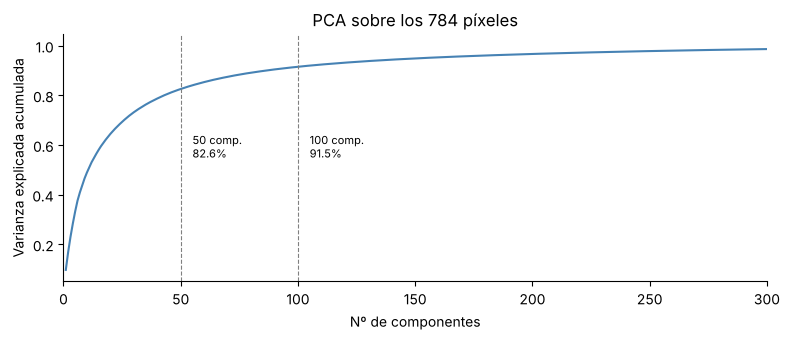

In [21]:
from sklearn.decomposition import PCA

pca_full = PCA(random_state=SEMILLA).fit(X_tr)
var_acum = np.cumsum(pca_full.explained_variance_ratio_)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(np.arange(1, 785), var_acum, color='steelblue')
for n in [50, 100]:
    ax.axvline(n, ls='--', color='gray', lw=0.8)
    ax.text(n + 5, 0.55, f'{n} comp.\n{var_acum[n - 1]:.1%}', fontsize=8)
ax.set_xlabel('Nº de componentes')
ax.set_ylabel('Varianza explicada acumulada')
ax.set_title('PCA sobre los 784 píxeles')
ax.set_xlim(0, 300)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

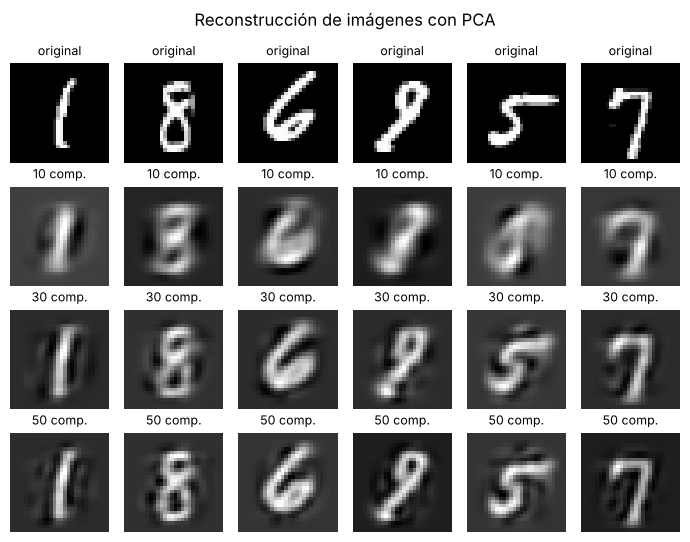

In [22]:
# ¿Qué se "ve" al comprimir con PCA? Reconstruimos algunas imágenes con pocos componentes
ejemplos = X_val[:6]
filas_img, titulos = [ejemplos], ['original'] * 6
for n in [10, 30, 50]:
    p = PCA(n_components=n, random_state=SEMILLA).fit(X_tr)
    filas_img.append(p.inverse_transform(p.transform(ejemplos)))
    titulos += [f'{n} comp.'] * 6

mostrar_rejilla(np.concatenate(filas_img), titulos, 4, 6,
                'Reconstrucción de imágenes con PCA', figsize=(7, 5.5))

Con **50 componentes** el dígito sigue siendo perfectamente reconocible y hemos pasado de 784 a 50 números por imagen. Entrenamos el pipeline completo y lo evaluamos en validación (puede tardar uno o dos minutos):

In [23]:
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

modelo = make_pipeline(
    PCA(n_components=50, whiten=True, random_state=SEMILLA),
    SVC(kernel='rbf', C=10, gamma='scale'),
)

t0 = time.time()
modelo.fit(X_tr, y_tr)
print(f'Entrenamiento: {time.time() - t0:.1f} s')

t0 = time.time()
pred_val = modelo.predict(X_val)
print(f'Predicción:    {time.time() - t0:.1f} s')
print(f'\nAccuracy en validación: {accuracy_score(y_val, pred_val):.4f}')

Entrenamiento: 17.4 s


Predicción:    5.3 s

Accuracy en validación: 0.9829


              precision    recall  f1-score   support

           0      0.984     0.992     0.988       827
           1      0.990     0.996     0.993       937
           2      0.981     0.983     0.982       835
           3      0.984     0.974     0.979       870
           4      0.986     0.986     0.986       814
           5      0.970     0.975     0.972       759
           6      0.989     0.993     0.991       827
           7      0.980     0.986     0.983       880
           8      0.984     0.972     0.978       813
           9      0.978     0.970     0.974       838

    accuracy                          0.983      8400
   macro avg      0.983     0.983     0.983      8400
weighted avg      0.983     0.983     0.983      8400



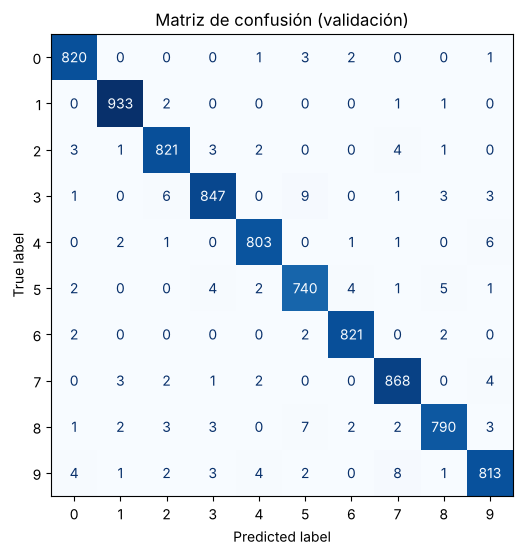

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

print(classification_report(y_val, pred_val, digits=3))

fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Matriz de confusión (validación)')
plt.show()

### ¿En qué se equivoca el modelo?

Visualizar los errores es tan importante como la métrica: a veces el modelo falla con dígitos que incluso a una persona le costaría leer, y otras veces descubrimos **etiquetas mal puestas** en los datos.

144 errores de 8400 imágenes de validación


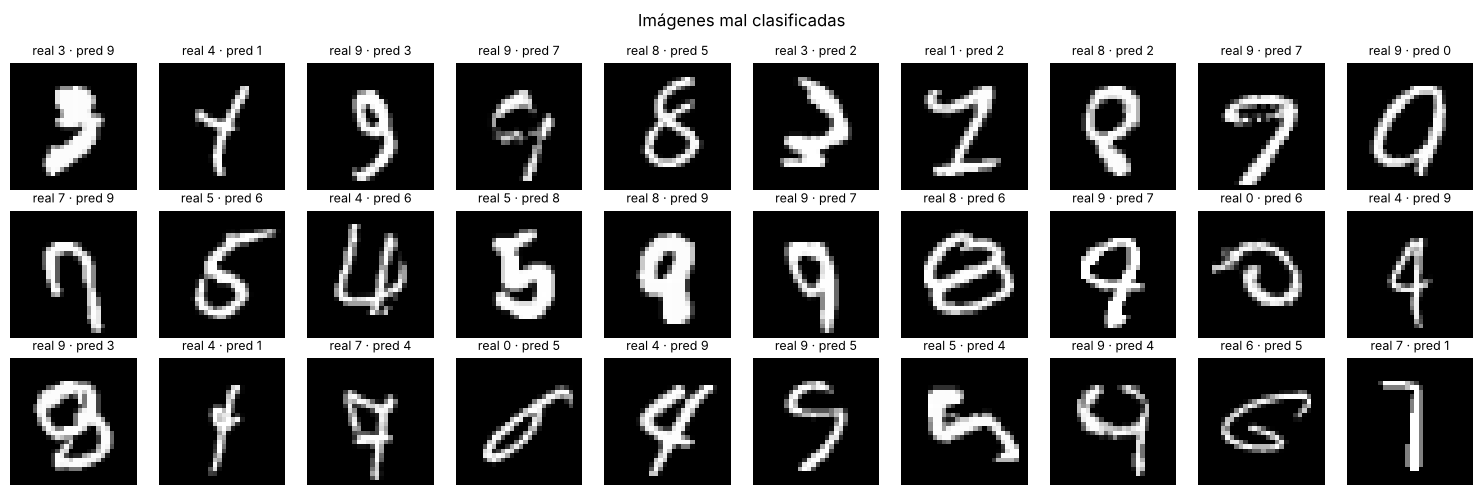

In [25]:
errores = np.where(pred_val != y_val)[0]
print(f'{len(errores)} errores de {len(y_val)} imágenes de validación')

sel = errores[:30]
mostrar_rejilla(X_val[sel], [f'real {y_val[k]} · pred {pred_val[k]}' for k in sel],
                3, 10, 'Imágenes mal clasificadas', figsize=(15, 5))

## A.9 Generación del fichero `submission.csv`

Para la entrega final:

1. **Reentrenamos** el modelo con **todo** `train.csv` (entrenamiento + validación): más datos suelen dar un modelo algo mejor.
2. **Predecimos** las 28 000 imágenes de `test.csv`.
3. Construimos el CSV con el formato exacto que pide Kaggle (`sample_submission.csv`):
   - Columna `ImageId`: número de imagen **empezando en 1** (no en 0).
   - Columna `Label`: dígito predicho.

In [26]:
sample = pd.read_csv(DATOS / 'sample_submission.csv')
print('Formato esperado:', list(sample.columns), '·', len(sample), 'filas')
sample.head()

Formato esperado: ['ImageId', 'Label'] · 28000 filas


,ImageId,Label
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0


In [27]:
t0 = time.time()
modelo.fit(X_norm, y_arr)
print(f'Reentrenado con {len(X_norm)} imágenes en {time.time() - t0:.1f} s')

t0 = time.time()
pred_test = modelo.predict(test_norm)
print(f'Predichas {len(pred_test)} imágenes de test en {time.time() - t0:.1f} s')

Reentrenado con 42000 imágenes en 23.8 s


Predichas 28000 imágenes de test en 22.6 s


In [28]:
submission = pd.DataFrame({
    'ImageId': np.arange(1, len(pred_test) + 1),
    'Label': pred_test.astype(int),
})

# Comprobaciones antes de entregar
assert list(submission.columns) == list(sample.columns), 'Columnas incorrectas'
assert len(submission) == len(sample), 'Número de filas incorrecto'
assert (submission['ImageId'].values == sample['ImageId'].values).all(), 'ImageId no coincide'
assert submission['Label'].between(0, 9).all(), 'Etiquetas fuera de rango'

submission.to_csv(DATOS / 'submission.csv', index=False)
print('submission.csv guardado ✔')
submission.head()

submission.csv guardado ✔


,ImageId,Label
0,1,2
1,2,0
2,3,9
3,4,9
4,5,3


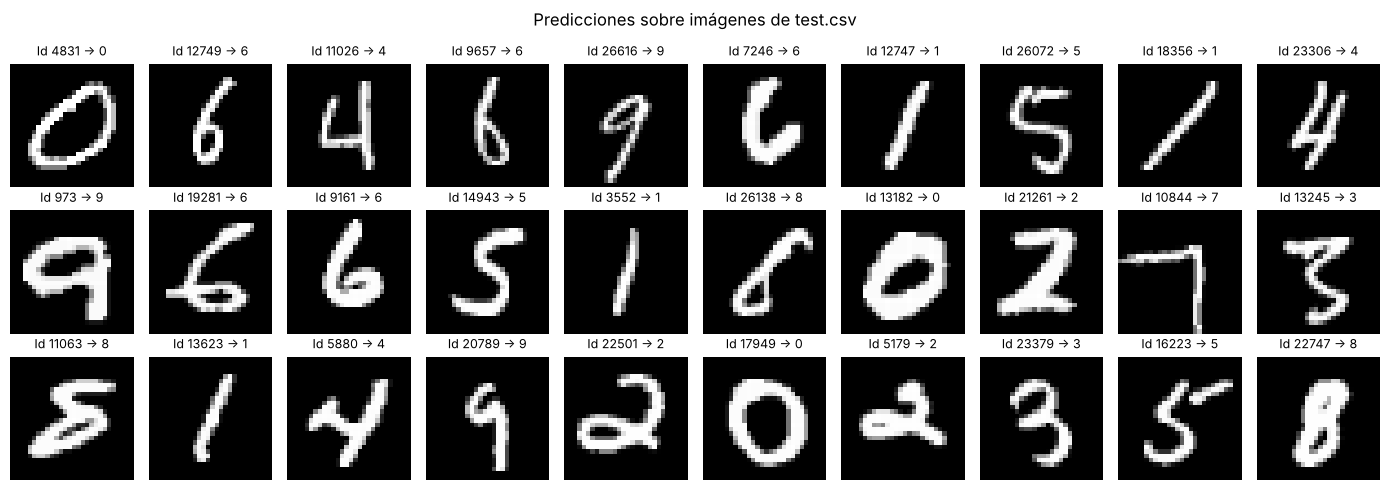

In [29]:
# Comprobación visual: ¿coinciden las predicciones con lo que vemos?
muestra_t = np.random.choice(len(test), 30, replace=False)
mostrar_rejilla(test.values[muestra_t],
                [f'Id {k + 1} → {pred_test[k]}' for k in muestra_t],
                3, 10, 'Predicciones sobre imágenes de test.csv', figsize=(14, 5))

In [30]:
# Distribución de las predicciones: debería parecerse a la de train
comp = pd.DataFrame({
    'train (%)': y.value_counts(normalize=True).sort_index() * 100,
    'predicción test (%)': submission['Label'].value_counts(normalize=True).sort_index() * 100,
}).round(1)
comp

,train (%),predicción test (%)
0,9.8,9.9
1,11.2,11.4
2,9.9,10.2
3,10.4,9.9
4,9.7,9.9
5,9.0,9.0
6,9.8,9.8
7,10.5,10.3
8,9.7,9.8
9,10.0,9.8


## A.10 Subida a Kaggle y resumen

### Cómo entregar

**Opción 1 — Web:** en la página de la competición, pestaña *Submit Predictions* → arrastrar `submission.csv` → *Submit*. En unos segundos aparece la puntuación (*accuracy* sobre el test público).

**Opción 2 — Kaggle CLI** (requiere `pip install kaggle` y el token `kaggle.json` en `~/.kaggle/`):

```bash
kaggle competitions submit -c digit-recognizer -f submission.csv -m "PCA(50) + SVC RBF"
```

Con este modelo cabe esperar una puntuación en torno a **0,98**, coherente con la *accuracy* obtenida en validación.

### Resumen

| Concepto | Lo que hemos visto |
|---|---|
| Imagen digital | Matriz de píxeles `uint8` (0–255): `alto × ancho` en grises, `alto × ancho × 3` en color |
| Imagen en CSV | Se **aplana** fila a fila (row-major): 28×28 → 784 columnas; `pixel_k` con `k = i·28 + j` |
| Reconstrucción | `fila.reshape(28, 28)` y `plt.imshow` |
| Eficiencia | `dtype='uint8'` reduce la memoria ×8; NPY/NPZ ocupan mucho menos que CSV y conservan la forma |
| Datasets reales | Un PNG/JPG por imagen con carpetas por clase, o contenedores binarios (HDF5, TFRecord) |
| Preparación | Normalizar a [0, 1], separar validación estratificada |
| Entrega | `ImageId` empezando en 1 + `Label`, validado contra `sample_submission.csv` |

### Para practicar

1. Cambia el número de componentes del PCA (20, 100, 150) y compara la *accuracy* en validación.
2. Sustituye el `SVC` por un `KNeighborsClassifier` o un `RandomForestClassifier`. ¿Cuál es más rápido? ¿Cuál acierta más?
3. Exporta **todo** `train.csv` a PNG en carpetas por clase y mide el tiempo de escritura y lectura frente al NPZ.
4. Busca la competición *Fashion-MNIST* en Kaggle: tiene exactamente el mismo formato CSV. ¿Funciona este cuaderno cambiando solo los ficheros?